# 02 - Train Next-Shot Model (GRU)

Runs on **Google Colab with a T4 GPU**. Run each cell top to bottom.

Downloads ShuttleSet22, maps the Chinese shot types to the 5 classes, builds last-4 -> next windows (a serve CAN be a target), trains a GRU with weighted loss, and saves the model + metrics to Drive.

In [8]:
import torch
assert torch.cuda.is_available(), 'No GPU active. In Colab: Runtime > Change runtime type > T4 GPU, then re-run this cell.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
drive.mount('/content/drive')
!pip install -q seaborn

GPU: NVIDIA L4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}
PAD_TOKEN     = NUM_CLASSES
SEQ_LEN       = 4
SEED          = 42

DRIVE          = '/content/drive/MyDrive/BadmintonFYP'
MODELS         = DRIVE + '/model23'
SHUTTLESET_DIR = '/content/ShuttleSet22'

SHUTTLE_MAP = {
    '發短球': 0, '發長球': 0,
    '挑球': 1, '防守回挑': 1,
    '長球': 2, '平球': 2, '小平球': 2, '後場抽平球': 2, '防守回抽': 2,
    '切球': 3, '過度切球': 3, '過渡切球': 3, '放小球': 3, '擋小球': 3, '勾球': 3, '推球': 3,
    '殺球': 4, '點扣': 4, '撲球': 4,
}

import os
os.makedirs(MODELS, exist_ok=True)
print('Classes:', DISPLAY_NAMES)
print('Mapped shot types:', len(SHUTTLE_MAP))

Classes: ['Short Serve', 'Lift', 'Clear', 'Drop Shot', 'Smash']
Mapped shot types: 19


In [10]:
import os, json, urllib.request, zipfile, shutil
from collections import Counter
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

SET_FOLDER = SHUTTLESET_DIR + '/set'
if not (os.path.isdir(SET_FOLDER) and os.listdir(SET_FOLDER)):
    url = 'https://github.com/wywyWang/CoachAI-Projects/archive/refs/heads/main.zip'
    zp = '/content/coachai.zip'
    print('Downloading ShuttleSet22 ...')
    urllib.request.urlretrieve(url, zp)
    with zipfile.ZipFile(zp) as z:
        z.extractall('/content/_ca')
    src = '/content/_ca/CoachAI-Projects-main/CoachAI-Challenge-IJCAI2023/ShuttleSet22'
    if os.path.exists(SHUTTLESET_DIR): shutil.rmtree(SHUTTLESET_DIR)
    shutil.move(src, SHUTTLESET_DIR)
    print('Ready at', SHUTTLESET_DIR)
print('set folder present:', os.path.isdir(SET_FOLDER))

Device: cuda
set folder present: True


In [ ]:
def parse_rallies(set_folder):
    rallies, skipped = [], []
    for match in os.listdir(set_folder):
        mp = os.path.join(set_folder, match)
        if not os.path.isdir(mp): continue
        for sf in ('set1.csv', 'set2.csv', 'set3.csv'):
            path = os.path.join(mp, sf)
            if not os.path.exists(path): continue
            try:
                d = pd.read_csv(path)
            except Exception as e:
                print('read err', e); continue
            if 'rally' not in d.columns or 'type' not in d.columns: continue
            for rid, rd in d.groupby('rally'):
                shots = []
                for t in rd['type'].astype(str).str.strip():
                    if t in SHUTTLE_MAP: shots.append(SHUTTLE_MAP[t])
                    else: skipped.append(t)
                if len(shots) >= 2:
                    rallies.append({'match_id': match, 'shots': shots})
    if skipped: print('skipped', len(skipped), 'unmapped types:', sorted(set(skipped)))
    return rallies

def build_windows(rallies, seq_len=SEQ_LEN):
    w = []
    for r in rallies:
        s = r['shots']
        for i in range(len(s)):
            hist = s[max(0, i - seq_len):i]
            if len(hist) < seq_len:
                hist = [PAD_TOKEN] * (seq_len - len(hist)) + hist
            w.append({'input': hist, 'target': s[i], 'match_id': r['match_id']})
    return w

def group_split(windows, val=0.15, test=0.15, seed=SEED):
    df = pd.DataFrame(windows)
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.match_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.match_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)

class SequenceDataset(Dataset):
    def __init__(self, df):
        self.x = [torch.tensor(a, dtype=torch.long) for a in df['input']]
        self.y = torch.tensor(df['target'].values, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

def class_weights(dtr):
    cnt = dtr['target'].value_counts().sort_index(); tot = len(dtr)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)

class ShotPredictorGRU(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed=32, hidden=128, layers=2, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(num_classes + 1, embed, padding_idx=PAD_TOKEN)
        self.gru = nn.GRU(embed, hidden, layers, batch_first=True, dropout=drop if layers > 1 else 0)
        self.fc = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, num_classes))
    def forward(self, x):
        x = self.emb(x); o, _ = self.gru(x); return self.fc(o[:, -1, :])

def evaluate(m, loader):
    m.eval(); P, L, t3, n = [], [], 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            lg = m(x.to(DEVICE)).cpu()
            P += lg.argmax(1).tolist(); L += y.tolist()
            t3 += (lg.topk(3, 1).indices == y.unsqueeze(1)).any(1).float().sum().item(); n += len(y)
    return accuracy_score(L, P), f1_score(L, P, average='macro'), t3 / n, P, L

print('defs ready')

defs ready


In [12]:
rallies = parse_rallies(SET_FOLDER)
print('rallies', len(rallies))
windows = build_windows(rallies)
print('windows', len(windows))
cc = Counter(w['target'] for w in windows); tot = sum(cc.values())
for i in range(NUM_CLASSES):
    print(' ', ID_TO_NAME[i], cc.get(i, 0), '%.1f%%' % (100 * cc.get(i, 0) / tot))
df_train, df_val, df_test = group_split(windows)
print('train', len(df_train), 'val', len(df_val), 'test', len(df_test))

skipped 1078 unmapped types: ['未知球種']
rallies 4743
windows 51173
  Short Serve 4036 7.9%
  Lift 9434 18.4%
  Clear 7086 13.8%
  Drop Shot 23574 46.1%
  Smash 7043 13.8%
train 34558 val 8052 test 8563


In [13]:
train_loader = DataLoader(SequenceDataset(df_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(SequenceDataset(df_val), batch_size=64)
test_loader  = DataLoader(SequenceDataset(df_test), batch_size=64)

model = ShotPredictorGRU().to(DEVICE)
print('params', sum(p.numel() for p in model.parameters()))
crit = nn.CrossEntropyLoss(weight=class_weights(df_train).to(DEVICE))
opt = optim.Adam(model.parameters(), lr=1e-3)

CKPT = MODELS + '/sequence_model.pth'
best = 0.0
for ep in range(20):
    model.train()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step()
    va, vf, vt3, _, _ = evaluate(model, val_loader)
    tag = ''
    if vf > best:
        best = vf; torch.save(model.state_dict(), CKPT); tag = ' saved'
    print('epoch', ep + 1, 'val_acc %.3f f1 %.3f top3 %.3f' % (va, vf, vt3), tag)
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
print('best val macro-F1 %.3f' % best)

params 178629
epoch 1 val_acc 0.463 f1 0.508 top3 0.964  saved
epoch 2 val_acc 0.447 f1 0.488 top3 0.965 
epoch 3 val_acc 0.453 f1 0.500 top3 0.966 
epoch 4 val_acc 0.471 f1 0.518 top3 0.966  saved
epoch 5 val_acc 0.464 f1 0.509 top3 0.965 
epoch 6 val_acc 0.463 f1 0.511 top3 0.966 
epoch 7 val_acc 0.442 f1 0.495 top3 0.966 
epoch 8 val_acc 0.506 f1 0.533 top3 0.965  saved
epoch 9 val_acc 0.430 f1 0.489 top3 0.966 
epoch 10 val_acc 0.459 f1 0.509 top3 0.956 
epoch 11 val_acc 0.463 f1 0.513 top3 0.966 
epoch 12 val_acc 0.477 f1 0.513 top3 0.965 
epoch 13 val_acc 0.469 f1 0.508 top3 0.966 
epoch 14 val_acc 0.469 f1 0.518 top3 0.966 
epoch 15 val_acc 0.427 f1 0.484 top3 0.965 
epoch 16 val_acc 0.461 f1 0.510 top3 0.965 
epoch 17 val_acc 0.457 f1 0.501 top3 0.965 
epoch 18 val_acc 0.463 f1 0.509 top3 0.966 
epoch 19 val_acc 0.463 f1 0.512 top3 0.966 
epoch 20 val_acc 0.469 f1 0.510 top3 0.965 
best val macro-F1 0.533


TEST acc 0.5346 macro-F1 0.5665 top-3 0.9708
              precision    recall  f1-score   support

 Short Serve       0.87      1.00      0.93       681
        Lift       0.45      0.67      0.54      1716
       Clear       0.41      0.34      0.37      1253
   Drop Shot       0.69      0.44      0.53      3763
       Smash       0.38      0.59      0.46      1150

    accuracy                           0.53      8563
   macro avg       0.56      0.61      0.57      8563
weighted avg       0.57      0.53      0.53      8563



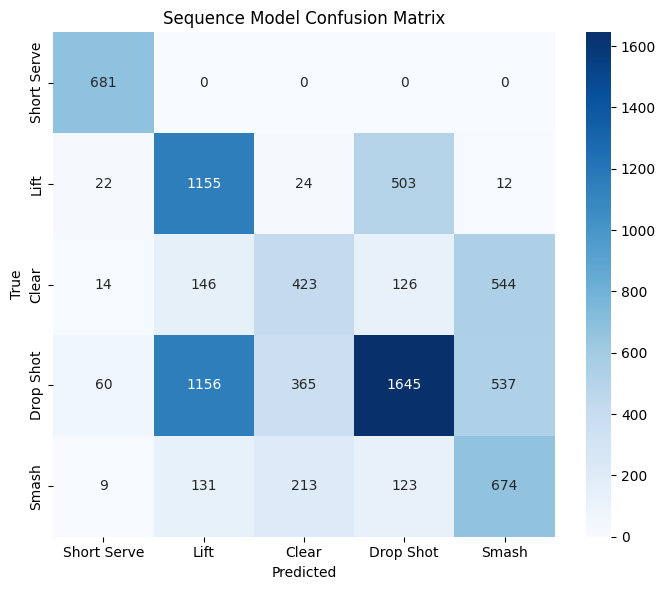

Saved sequence model + metrics + confusion matrix to /content/drive/MyDrive/BadmintonFYP/model23


In [14]:
import seaborn as sns, matplotlib.pyplot as plt
acc, f1, top3, P, L = evaluate(model, test_loader)
print('TEST acc %.4f macro-F1 %.4f top-3 %.4f' % (acc, f1, top3))
print(classification_report(L, P, labels=list(range(NUM_CLASSES)), target_names=DISPLAY_NAMES))
cm = confusion_matrix(L, P, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Sequence Model Confusion Matrix')
plt.tight_layout(); plt.savefig(MODELS + '/sequence_confusion_matrix.png', dpi=150); plt.show()
json.dump({'test_accuracy': acc, 'test_macro_f1': f1, 'test_top3': top3, 'best_val_macro_f1': best},
          open(MODELS + '/sequence_metrics.json', 'w'), indent=2)
print('Saved sequence model + metrics + confusion matrix to', MODELS)